# Prédiction de pluie — Régression logistique

Pipeline complet de régression logistique pour prédire la pluie du lendemain (`RainTomorrow`) sur le jeu de données WeatherAUS.

Ce notebook consomme directement les exports du notebook `4_preprocessing_imputation` (`weatherAUS_X_train.csv`, `weatherAUS_X_test.csv`, `weatherAUS_y_train.csv`, `weatherAUS_y_test.csv`) : le découpage chronologique, l'imputation MICE par groupe climatique, l'encodage cyclique des directions de vent et la sélection des variables y sont déjà réalisés.

Chaque section explique *ce que* fait l'étape. Les sorties numériques sont dupliquées dans `LR_result.txt` ; chaque figure est enregistrée en PNG dans `figures/`. Ces deux artefacts alimentent un rapport écrit après l'exécution du notebook.


## 1. Imports et constantes


In [10]:
import os
import sys
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    GridSearchCV, TimeSeriesSplit, learning_curve,
)
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
    roc_curve, roc_auc_score, precision_recall_curve, auc,
    brier_score_loss, log_loss,
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

RANDOM_STATE = 42
MODELS_DIR = Path('../models/logistic_regression')
TEST_CUTOFF = pd.Timestamp('2016-01-01')   # train < cutoff <= test

### Configuration des sorties

Trois emplacements sont créés à côté de ce notebook : un dossier `figures/`, un fichier `LR_result.txt`, et le dossier de modèles `../models/logistic_regression/`. `sys.stdout` est dupliqué (tee) afin que chaque `print(...)` soit également écrit dans le fichier de résultats. Chaque graphique est enregistré avec `save_fig(...)` avant `plt.show()`.

Chaque modèle entraîné est sérialisé avec `joblib` dans un *bundle* — un dictionnaire contenant le modèle, le seuil de décision associé, la liste ordonnée des variables, le `StandardScaler` ajusté sur le train et les métriques de test. Sans le scaler et la liste de variables, un modèle rechargé ne serait pas réutilisable : les entrées de production doivent subir exactement la même transformation que le train.


In [11]:
# Créer les emplacements de sortie
os.makedirs('../reports/figures/logistic_regression', exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

_LR_RESULT_PATH = 'LR_result.txt'
_LR_RESULT_FILE = open(_LR_RESULT_PATH, 'w', encoding='utf-8')

class _Tee:
    """Écrit à la fois vers la sortie standard réelle et le fichier de résultats."""
    def __init__(self, *streams):
        self._streams = streams
    def write(self, data):
        for s in self._streams:
            s.write(data)
    def flush(self):
        for s in self._streams:
            s.flush()
    def isatty(self):
        return False

_ORIG_STDOUT = sys.stdout
sys.stdout = _Tee(_ORIG_STDOUT, _LR_RESULT_FILE)

print(f'# Logistic Regression — numerical outputs')
print(f'# Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')

def log_section(title):
    """Affiche une bannière de section pour que LR_result.txt soit facile à parcourir."""
    bar = '=' * 72
    print(f'\n{bar}\n{title}\n{bar}')

def save_fig(name, fig=None):
    """Enregistre la figure courante (ou celle fournie) dans figures/<name>.png à 150 dpi."""
    if fig is None:
        fig = plt.gcf()
    path = f'../reports/figures/logistic_regression/{name}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'  [saved {path}]')


## 2. Chargement des données prétraitées

Les entrées sont les quatre exports du notebook `4_preprocessing_imputation` :

| Fichier | Contenu |
|---|---|
| `weatherAUS_X_train.csv` | Variables explicatives, période < `TEST_CUTOFF` |
| `weatherAUS_X_test.csv` | Variables explicatives, période >= `TEST_CUTOFF` |
| `weatherAUS_y_train.csv` | Cible `RainTomorrow` (train) |
| `weatherAUS_y_test.csv` | Cible `RainTomorrow` (test) |

Ces fichiers sont déjà imputés (MICE par groupe climatique, ajusté sur le train uniquement), déjà mis à l'échelle (`RobustScaler`, ajusté sur le train uniquement) et déjà nettoyés des colonnes non retenues. Trois assertions vérifient l'alignement des colonnes, l'absence de valeurs manquantes et le caractère strictement numérique de la matrice de variables — si l'une d'elles échoue, le contrat d'interface avec le notebook de prétraitement a changé.

La cible est reconvertie en booléen pour rester cohérente avec les conventions d'affichage des matrices de confusion de ce notebook.

In [12]:
log_section('2. Data loading')

DATA_DIR = Path('../data')

X_train = pd.read_csv(DATA_DIR / 'weatherAUS_X_train.csv')
X_test  = pd.read_csv(DATA_DIR / 'weatherAUS_X_test.csv')
y_train = pd.read_csv(DATA_DIR / 'weatherAUS_y_train.csv').squeeze('columns').astype(bool)
y_test  = pd.read_csv(DATA_DIR / 'weatherAUS_y_test.csv').squeeze('columns').astype(bool)

# Contrat d'interface avec le notebook de prétraitement
assert list(X_train.columns) == list(X_test.columns), 'Colonnes train/test désalignées'
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, 'NaN résiduels'
assert X_train.select_dtypes(exclude=[np.number]).empty, 'Colonnes non numériques résiduelles'
assert len(X_train) == len(y_train) and len(X_test) == len(y_test), 'X et y désalignés'

print(f'X_train : {X_train.shape[0]:,} rows x {X_train.shape[1]} columns')
print(f'X_test  : {X_test.shape[0]:,} rows x {X_test.shape[1]} columns')
print(f'Split   : {len(X_train) / (len(X_train) + len(X_test)):.1%} train / {len(X_test) / (len(X_train) + len(X_test)):.1%} test')
print(f'\nColumns ({X_train.shape[1]}):')
for col in X_train.columns:
    print(f'  - {col}')

print(f'\nTrain rain proportion : {y_train.mean():.4%}')
print(f'Test  rain proportion : {y_test.mean():.4%}')
print(f'Drift (test - train)  : {(y_test.mean() - y_train.mean()) * 100:+.2f} percentage points')


## 3. Variables retenues — décisions prises en amont

Aucune ingénierie de variables n'est effectuée ici : la matrice reçue est celle produite par le notebook de prétraitement. Pour mémoire, les colonnes suivantes ont été écartées en amont, et les justifications ci-dessous sont reprises dans le rapport :

- **Membres redondants d'une paire.** `Humidity9am` est supprimée au profit de `Humidity3pm`, plus prédictive.
- **Identité géographique.** `Location` est retirée afin que le modèle s'appuie uniquement sur le signal météorologique, et non sur des taux de base propres à chaque station.
- **Labels discrets de direction du vent.** `WindGustDir`, `WindDir9am` et `WindDir3pm` sont remplacées par les paires sinus/cosinus créées lors de l'imputation cyclique, qui portent la même information sans introduire de variable catégorielle à 16 niveaux.
- **`RainToday`.** Écartée comme quasi-fuite : le modèle reçoit déjà l'ensemble des observations du jour courant.
- **`Month` et `weather_trend_group`.** La saisonnalité est portée par `Date_sin` / `Date_cos` ; le groupe de tendance a servi à segmenter l'imputation, pas à prédire.

**Réserve méthodologique à mentionner dans le rapport.** `weather_trend_group` a été obtenu par KMeans sur l'intégralité du jeu de données, donc en incluant la période de test. Cette variable ne figure pas parmi les prédicteurs, mais elle a conditionné le partitionnement de l'imputation MICE : une fuite temporelle résiduelle, faible mais réelle, subsiste de ce fait.

## 4. Découpage chronologique train/test (réalisé en amont)

L'EDA a mis en évidence l'autocorrélation temporelle intra-station comme la violation de l'hypothèse IID dans ce jeu de données. Un découpage aléatoire en k-fold ou stratifié placerait le jour $t$ d'une station $s$ dans l'entraînement et le jour $t+1$ de la même station dans le test ; l'autocorrélation de lag 1 $r \approx 0.46$ établie en EDA §6 deviendrait alors un signal gratuit qui ne correspond à rien d'atteignable en déploiement réel.

Le notebook de prétraitement découpe donc de manière chronologique : entraînement < 2016-01-01, test à partir de 2016-01-01. Toute validation croisée pendant l'entraînement utilise `TimeSeriesSplit`, qui produit des plis en ordre chronologique croissant — chaque pli de validation ne contient que des dates postérieures à son pli d'entraînement. C'est l'évaluation standard « one-step-ahead » pour les séries temporelles stationnaires.

**Condition à vérifier.** `TimeSeriesSplit` découpe sur l'ordre des lignes, pas sur une colonne de dates. Il faut donc que `X_train` soit trié chronologiquement. Le notebook de prétraitement filtre sur `Date` sans trier au préalable : l'ordre exporté est celui du CSV source, qui est probablement groupé par station. La cellule suivante rétablit l'ordre chronologique si les dates ont été exportées, et avertit sinon — dans ce cas, la validation croisée, la sélection de seuil (§8) et la courbe d'apprentissage (§12) découperaient par blocs de stations et perdraient leur interprétation temporelle.

Pour produire les fichiers de dates, ajouter cette cellule à la fin du notebook `4_preprocessing_imputation` :

```python
df_train[['Date']].to_csv("../data/weatherAUS_dates_train.csv", index=False)
df_test[['Date']].to_csv("../data/weatherAUS_dates_test.csv", index=False)
```

L'ordre de `X_test` est indifférent : il ne sert qu'au calcul des métriques finales.

In [13]:
log_section('4. Chronological ordering check')

DATES_TRAIN_PATH = DATA_DIR / 'weatherAUS_dates_train.csv'

if DATES_TRAIN_PATH.exists():
    dates_train = pd.to_datetime(pd.read_csv(DATES_TRAIN_PATH).squeeze('columns'))
    assert len(dates_train) == len(X_train), 'Fichier de dates désaligné avec X_train'

    already_sorted = dates_train.is_monotonic_increasing
    order = dates_train.sort_values(kind='mergesort').index   # tri stable
    X_train = X_train.loc[order].reset_index(drop=True)
    y_train = y_train.loc[order].reset_index(drop=True)
    dates_train = dates_train.loc[order].reset_index(drop=True)

    print(f'Dates trouvées : {DATES_TRAIN_PATH}')
    print(f'Ordre source déjà chronologique : {already_sorted}')
    print(f'Train réordonné : {dates_train.min().date()} -> {dates_train.max().date()}')
else:
    dates_train = None
    print(f'AVERTISSEMENT : {DATES_TRAIN_PATH} introuvable.')
    print('  L\'ordre chronologique de X_train ne peut pas être vérifié.')
    print('  Les plis de TimeSeriesSplit (§6, §8, §12) risquent de ne pas être temporels.')


In [14]:
# Le prétraitement applique un RobustScaler (centrage médiane, division par l'IQR) : les
# variables ne sont donc pas à variance unitaire, ce qui compte pour une pénalisation L1/L2.
# On standardise par-dessus, en n'ajustant que sur le train (aucune fuite ajoutée).
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)
print(f'Scaled {X_train_scaled.shape[1]} numeric features (fit on train only).')


## 5. Modèle de référence

`LogisticRegression` par défaut, sans pondération de classe et avec le seuil par défaut de 0,5. 

Cela établit le plancher : toute amélioration ultérieure doit démontrer un gain mesurable par rapport à cette configuration pour justifier la complexité ajoutée.

In [15]:
log_section('5. Baseline model')

baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
baseline.fit(X_train_scaled, y_train)
y_pred_baseline = baseline.predict(X_test_scaled)
y_proba_baseline = baseline.predict_proba(X_test_scaled)[:, 1]

print('Baseline classification report:')
print(classification_report(y_test, y_pred_baseline))
print(f'ROC-AUC: {roc_auc_score(y_test, y_proba_baseline):.4f}')


In [16]:
# Export — modèle de référence (seuil par défaut 0.5, aucune pondération)
path = MODELS_DIR / 'logistic_regression_baseline.joblib'
joblib.dump({'model': baseline, 'threshold': 0.5,
             'features': list(X_train_scaled.columns), 'scaler': scaler,
             'metrics': {'f1_yes': f1_score(y_test, y_pred_baseline),
                         'precision_yes': precision_score(y_test, y_pred_baseline),
                         'recall_yes': recall_score(y_test, y_pred_baseline),
                         'roc_auc': roc_auc_score(y_test, y_proba_baseline)}}, path)
print(f'  [saved {path}]')


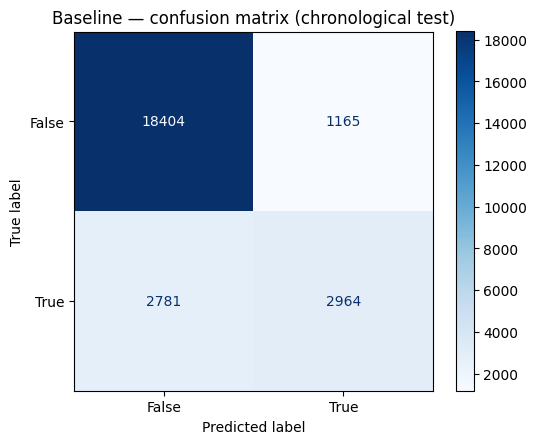

In [17]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test, y_pred_baseline)
ConfusionMatrixDisplay(cm, display_labels=baseline.classes_).plot(cmap='Blues', ax=ax)
ax.set_title('Baseline — confusion matrix (chronological test)')
plt.tight_layout()
save_fig('01_baseline_confusion_matrix', fig)
plt.show()


## 6. Optimisation des hyperparamètres avec TimeSeriesSplit

`GridSearchCV` sur $C$, la pénalité et `class_weight`, évalué sur le F1 de la classe pluie. L'itérateur de validation croisée est `TimeSeriesSplit(n_splits=5)` plutôt que le k-fold stratifié par défaut — chaque pli de validation ne contient que des dates de la période d'entraînement postérieures à son pli d'entraînement, ce qui reflète la tâche réelle de déploiement : prévoir la pluie de demain à partir des observations d'aujourd'hui.

In [18]:
log_section('6. Hyperparameter tuning')

param_grid = {
    'C':            [0.01, 0.1, 1, 10],
    'penalty':      ['l1', 'l2'],
    'solver':       ['liblinear'],
    'class_weight': [None, 'balanced'],
}

ts_cv = TimeSeriesSplit(n_splits=5)

grid_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    param_grid,
    cv=ts_cv,
    scoring='f1',
    n_jobs=-1,
)
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_
print(f'Best params : {grid_search.best_params_}')
print(f'Best CV F1  : {grid_search.best_score_:.4f}')


/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logist

In [19]:
y_pred_tuned = best_model.predict(X_test_scaled)
y_proba_tuned = best_model.predict_proba(X_test_scaled)[:, 1]

print('Tuned model — classification report:')
print(classification_report(y_test, y_pred_tuned))
print(f'ROC-AUC: {roc_auc_score(y_test, y_proba_tuned):.4f}')

# Diagnostic on coefficient sparsity (only meaningful under L1).
if grid_search.best_params_['penalty'] == 'l1':
    n_zero = int(np.sum(best_model.coef_ == 0))
    n_total = best_model.coef_.shape[1]
    print(f'L1 zeroed {n_zero}/{n_total} features at C={grid_search.best_params_["C"]}.')
else:
    print(f'L2 selected; coefficient sparsity is not applicable (L2 produces no exact zeros).')


## 7. Déséquilibre de classes — trois stratégies à $C = 1, \ell_1$ fixé

Trois traitements orthogonaux du déséquilibre ~78/22 : repondération de la fonction de perte (`class_weight='balanced'`), ajustement du seuil (sélectionné séparément en §8), et suréchantillonnage SMOTE. Les trois sont comparées à la même configuration de régularisation afin que les chiffres soient directement comparables.

L'usage de SMOTE sous évaluation chronologique est discutable — les points synthétiques de la classe minoritaire sont des interpolations entre jours de pluie de la période d'entraînement, et les appliquer à une période de test contenant une météo réellement nouvelle peut dégrader plutôt qu'améliorer la généralisation. Nous l'incluons par souci d'exhaustivité et rapportons le compromis.

Les matrices de confusion par stratégie suivent le tableau comparatif.

In [20]:
log_section('7. Class imbalance — three strategies')

results = []

# 7a — pondération de classe par défaut
m1 = LogisticRegression(C=1, penalty='l1', solver='liblinear',
                        max_iter=1000, random_state=RANDOM_STATE)
m1.fit(X_train_scaled, y_train)
p1 = m1.predict(X_test_scaled)
results.append({'config': 'default', 'F1': f1_score(y_test, p1),
                'precision': precision_score(y_test, p1),
                'recall': recall_score(y_test, p1)})

# 7b — poids de classe équilibrés
m2 = LogisticRegression(C=1, penalty='l1', solver='liblinear',
                        class_weight='balanced',
                        max_iter=1000, random_state=RANDOM_STATE)
m2.fit(X_train_scaled, y_train)
p2 = m2.predict(X_test_scaled)
results.append({'config': 'balanced weights', 'F1': f1_score(y_test, p2),
                'precision': precision_score(y_test, p2),
                'recall': recall_score(y_test, p2)})

# 7c — SMOTE
m3 = None
p3 = None
try:
    from imblearn.over_sampling import SMOTE
    smote = SMOTE(random_state=RANDOM_STATE)
    X_sm, y_sm = smote.fit_resample(X_train_scaled, y_train)
    m3 = LogisticRegression(C=1, penalty='l1', solver='liblinear',
                            max_iter=1000, random_state=RANDOM_STATE)
    m3.fit(X_sm, y_sm)
    p3 = m3.predict(X_test_scaled)
    results.append({'config': 'SMOTE', 'F1': f1_score(y_test, p3),
                    'precision': precision_score(y_test, p3),
                    'recall': recall_score(y_test, p3)})
    print(f'SMOTE training set: {len(y_sm):,} rows ({pd.Series(y_sm).mean():.0%} rain)')
except ImportError:
    print('imblearn not installed; SMOTE skipped.')

imbalance_df = pd.DataFrame(results).round(3)
print('\nImbalance comparison:')
print(imbalance_df.to_string(index=False))


/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C

In [21]:
# Export — trois traitements du déséquilibre, à C=1 et pénalité L1 fixés
# Seuil 0.5 : ces trois modèles sont comparés au point de fonctionnement par défaut.
for name, model, pred in [('logistic_regression_imbalance_default', m1, p1),
                          ('logistic_regression_imbalance_balanced', m2, p2),
                          ('logistic_regression_imbalance_smote', m3, p3)]:
    if model is None:
        print(f'  [skipped {name} — modèle non entraîné]')
        continue
    path = MODELS_DIR / f'{name}.joblib'
    joblib.dump({'model': model, 'threshold': 0.5,
                 'features': list(X_train_scaled.columns), 'scaler': scaler,
                 'metrics': {'f1_yes': f1_score(y_test, pred),
                             'precision_yes': precision_score(y_test, pred),
                             'recall_yes': recall_score(y_test, pred),
                             'roc_auc': roc_auc_score(y_test, model.predict_proba(X_test_scaled)[:, 1])}}, path)
    print(f'  [saved {path}]')


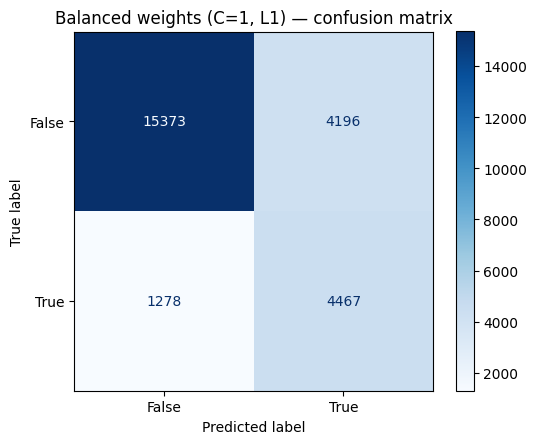

In [22]:
# Matrice de confusion — poids de classe équilibrés
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm = confusion_matrix(y_test, p2)
ConfusionMatrixDisplay(cm, display_labels=m2.classes_).plot(cmap='Blues', ax=ax)
ax.set_title('Balanced weights (C=1, L1) — confusion matrix')
plt.tight_layout()
save_fig('02_balanced_weights_confusion_matrix', fig)
plt.show()


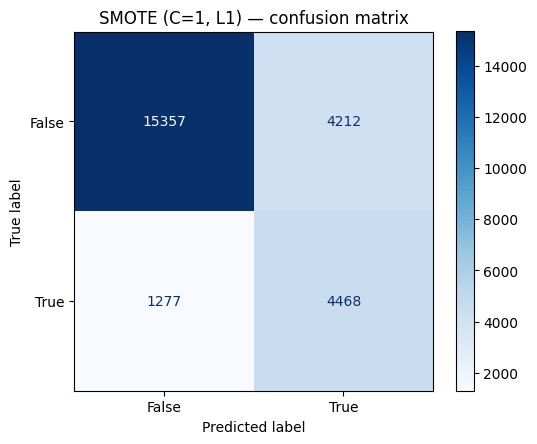

In [23]:
# Matrice de confusion — SMOTE
if m3 is not None and p3 is not None:
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    cm = confusion_matrix(y_test, p3)
    ConfusionMatrixDisplay(cm, display_labels=m3.classes_).plot(cmap='Blues', ax=ax)
    ax.set_title('SMOTE (C=1, L1) — confusion matrix')
    plt.tight_layout()
    save_fig('03_smote_confusion_matrix', fig)
    plt.show()
else:
    print('SMOTE confusion matrix skipped (imblearn unavailable).')


## 8. Sélection du seuil sur les plis d'entraînement (TimeSeriesSplit)

Le seuil de décision est sélectionné par validation croisée `TimeSeriesSplit` à 5 plis sur le jeu d'entraînement. Le critère de sélection n'est *pas* le F1 maximal ; c'est le seuil qui minimise le déséquilibre précision–rappel, défini par
$$D(t) = \big| P(t) - F_1(t) \big| + \big| F_1(t) - R(t) \big|,$$
où $P$, $R$, $F_1$ sont la précision, le rappel et le F1 moyens en validation sur les cinq plis au seuil $t$. Comme $F_1 = 2PR/(P+R)$ est la moyenne harmonique de $P$ et $R$, $D(t) = 0$ si et seulement si $P = R$, et $D(t) > 0$ sinon — donc $\arg\min_t D(t)$ est le seuil auquel précision et rappel se croisent.

Cela diffère substantiellement de $\arg\max_t F_1(t)$ : le F1 maximal choisit le seuil où le gain marginal de $P$ égale la perte marginale de $R$ (ou l'inverse), ce qui sur des données déséquilibrées avec un modèle orienté rappel aboutit typiquement à un seuil bas et un point de fonctionnement biaisé vers le rappel. Le critère de croisement précision-rappel choisit le seuil où les deux sont égaux, ce qui donne un unique nombre ($P = R$) décrivant le point de fonctionnement et constitue le critère pertinent lorsque le coût de déploiement d'un faux négatif équivaut à celui d'un faux positif.

Le balayage du seuil est restreint à $[0.60, 0.80]$ par pas de $0.01$. La borne inférieure est fixée au-dessus du seuil conventionnel de 0,5 car le modèle optimisé est entraîné avec `class_weight='balanced'` : son échelle de probabilité est décalée vers le haut (probabilité moyenne prédite $\approx 0.35$ contre un taux de base empirique de $0.20$, comme confirmé en §11), donc la région du seuil pertinente pour le F1 se situe au-dessus de 0,5 plutôt qu'en dessous.

In [24]:
log_section('8. Threshold selection (TimeSeriesSplit CV)')

thresholds = np.round(np.arange(0.6, 0.8, 0.01), 2)

fold_records = []
for tr_idx, val_idx in ts_cv.split(X_train_scaled):
    fm = LogisticRegression(**best_model.get_params())
    fm.fit(X_train_scaled.iloc[tr_idx], y_train.iloc[tr_idx])
    fold_records.append((
        y_train.iloc[val_idx].values,
        fm.predict_proba(X_train_scaled.iloc[val_idx])[:, 1],
    ))

rows = []
for t in thresholds:
    f1s = [f1_score(yt, yp >= t) for yt, yp in fold_records]
    precs = [precision_score(yt, yp >= t, zero_division=0) for yt, yp in fold_records]
    recs = [recall_score(yt, yp >= t) for yt, yp in fold_records]
    rows.append({'threshold': t, 'CV_F1_mean': np.mean(f1s), 'CV_F1_std': np.std(f1s),
                 'CV_precision': np.mean(precs), 'CV_recall': np.mean(recs)})
thresh_df = pd.DataFrame(rows)


/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C

In [25]:
thresh_df['diff'] = abs(thresh_df['CV_precision'] - thresh_df['CV_F1_mean']) + abs(thresh_df['CV_F1_mean'] - thresh_df['CV_recall'])


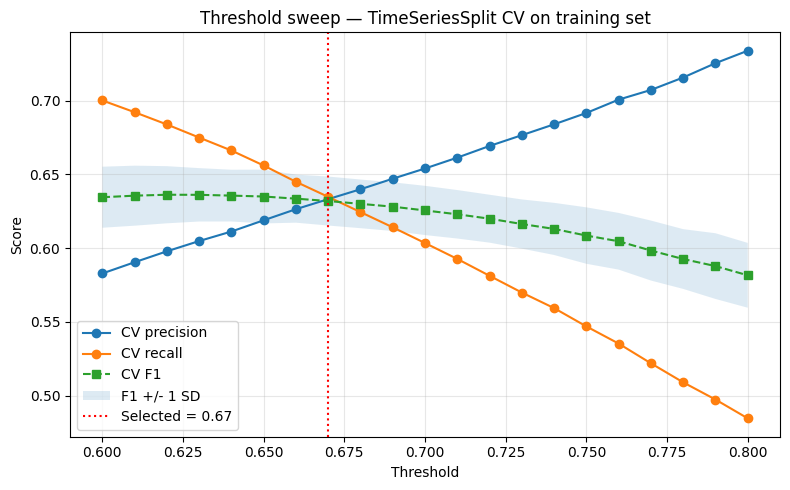

In [26]:
best_threshold = float(thresh_df.loc[thresh_df['diff'].idxmin(), 'threshold'])
print(f'CV-selected threshold: {best_threshold}')
print('\nThreshold sweep table:')
print(thresh_df.to_string(index=False, float_format='%.3f'))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresh_df['threshold'], thresh_df['CV_precision'], 'o-', label='CV precision')
ax.plot(thresh_df['threshold'], thresh_df['CV_recall'], 'o-', label='CV recall')
ax.plot(thresh_df['threshold'], thresh_df['CV_F1_mean'], 's--', label='CV F1')
ax.fill_between(thresh_df['threshold'],
                thresh_df['CV_F1_mean'] - thresh_df['CV_F1_std'],
                thresh_df['CV_F1_mean'] + thresh_df['CV_F1_std'],
                alpha=0.15, label='F1 +/- 1 SD')
ax.axvline(best_threshold, color='red', linestyle=':', label=f'Selected = {best_threshold}')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.set_title('Threshold sweep — TimeSeriesSplit CV on training set')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
save_fig('04_threshold_sweep', fig)
plt.show()

# Évaluation unique sur le jeu de test au seuil sélectionné
y_pred_thr = (y_proba_tuned >= best_threshold)
print(f'\nTest evaluation at threshold {best_threshold}:')
print(classification_report(y_test, y_pred_thr))


In [27]:
# Export — modèle optimisé par GridSearchCV, au seuil sélectionné en validation croisée
path = MODELS_DIR / 'logistic_regression_grid_search_tuned.joblib'
joblib.dump({'model': best_model, 'threshold': best_threshold,
             'features': list(X_train_scaled.columns), 'scaler': scaler,
             'best_params': grid_search.best_params_, 'cv_best_f1': grid_search.best_score_,
             'metrics': {'f1_yes': f1_score(y_test, y_pred_thr),
                         'precision_yes': precision_score(y_test, y_pred_thr),
                         'recall_yes': recall_score(y_test, y_pred_thr),
                         'roc_auc': roc_auc_score(y_test, y_proba_tuned),
                         'f1_yes_at_0.5': f1_score(y_test, y_pred_tuned)}}, path)
print(f'  [saved {path}]')


## 9. Termes d'interaction

Les 8 variables numériques les plus importantes par coefficient absolu sont sélectionnées à partir du modèle optimisé et passées dans `PolynomialFeatures(degree=2, interaction_only=True)` pour générer $\binom{8}{2} = 28$ termes d'interaction croisés. Le message de diagnostic indique le nombre de coefficients annulés selon la pénalité réellement utilisée ($\ell_1$ produit des zéros exacts ; $\ell_2$ non).

In [28]:
log_section('9. Interaction terms')

k = 8
importance_df = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'AbsCoef': np.abs(best_model.coef_[0]),
}).sort_values('AbsCoef', ascending=False)
top_k = importance_df['Feature'].head(k).tolist()
print(f'Top-{k} numeric features: {top_k}')

poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
poly.fit(X_train_scaled[top_k])
all_names = list(poly.get_feature_names_out(top_k))
cross_names = [n for n in all_names if ' ' in n]
cross_idx = [all_names.index(n) for n in cross_names]

def append_cross(X_base):
    arr = poly.transform(X_base[top_k])
    return pd.concat([X_base,
                      pd.DataFrame(arr[:, cross_idx], columns=cross_names, index=X_base.index)],
                     axis=1)

X_train_int = append_cross(X_train_scaled)
X_test_int = append_cross(X_test_scaled)

log_reg_int = LogisticRegression(**best_model.get_params())
log_reg_int.fit(X_train_int, y_train)
y_pred_int = log_reg_int.predict(X_test_int)
y_proba_int = log_reg_int.predict_proba(X_test_int)[:, 1]

# Diagnostic — dépend du type de pénalité
penalty_used = log_reg_int.get_params()['penalty']
coef_cross = log_reg_int.coef_[0][len(X_train_scaled.columns):]
n_zero_cross = int(np.sum(coef_cross == 0))
if penalty_used == 'l1':
    print(f'Penalty = L1: zeroed {n_zero_cross}/{len(cross_names)} interaction terms.')
else:
    print(f'Penalty = L2: zeroed-coefficient count is structurally 0 under L2 '
          f'(L2 shrinks toward zero but does not produce exact zeros). '
          f'All {len(cross_names)} interaction terms are retained.')

print(f'\nWith {len(cross_names)} interaction terms — classification report:')
print(classification_report(y_test, y_pred_int))
print(f'F1 (rain): {f1_score(y_test, y_pred_int):.4f}')
print(f'ROC-AUC : {roc_auc_score(y_test, y_proba_int):.4f}')


/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [29]:
# Export — modèle avec termes d'interaction
# Le bundle embarque `poly`, `top_k` et `cross_idx` : sans eux la matrice de variables
# étendue n'est pas reconstructible et le modèle est inutilisable.
path = MODELS_DIR / 'logistic_regression_interactions.joblib'
joblib.dump({'model': log_reg_int, 'threshold': best_threshold,
             'features': list(X_train_int.columns), 'scaler': scaler,
             'poly': poly, 'top_k': top_k, 'cross_names': cross_names, 'cross_idx': cross_idx,
             'metrics': {'f1_yes': f1_score(y_test, y_pred_int),
                         'precision_yes': precision_score(y_test, y_pred_int),
                         'recall_yes': recall_score(y_test, y_pred_int),
                         'roc_auc': roc_auc_score(y_test, y_proba_int)}}, path)
print(f'  [saved {path}]')


## 10. Stabilité des coefficients par bootstrap

Deux points de vue sur les coefficients du modèle optimisé :

- **Top-20 des coefficients absolus du modèle unique ajusté** — un classement rapide des variables sur lesquelles l'optimiseur s'est le plus appuyé.
- **$N = 200$ rééchantillonnages bootstrap** sur le jeu d'entraînement, réajustant le modèle optimisé sur chaque rééchantillon et conservant à la fois le vecteur de coefficients et les probabilités prédites sur le jeu de test. Les quantiles du bootstrap donnent des IC à 95 % ; les probabilités agrégées (bagging) donnent une prédiction d'ensemble au seuil de la §8.

Le bootstrap standard est techniquement indifférent à l'ordre chronologique — l'échantillonnage avec remise brouille les dates — mais pour la stabilité des coefficients sous l'hypothèse de physique stationnaire, cela reste acceptable. Un bootstrap par blocs serait nécessaire si l'on cherchait à caractériser la structure d'autocorrélation elle-même.

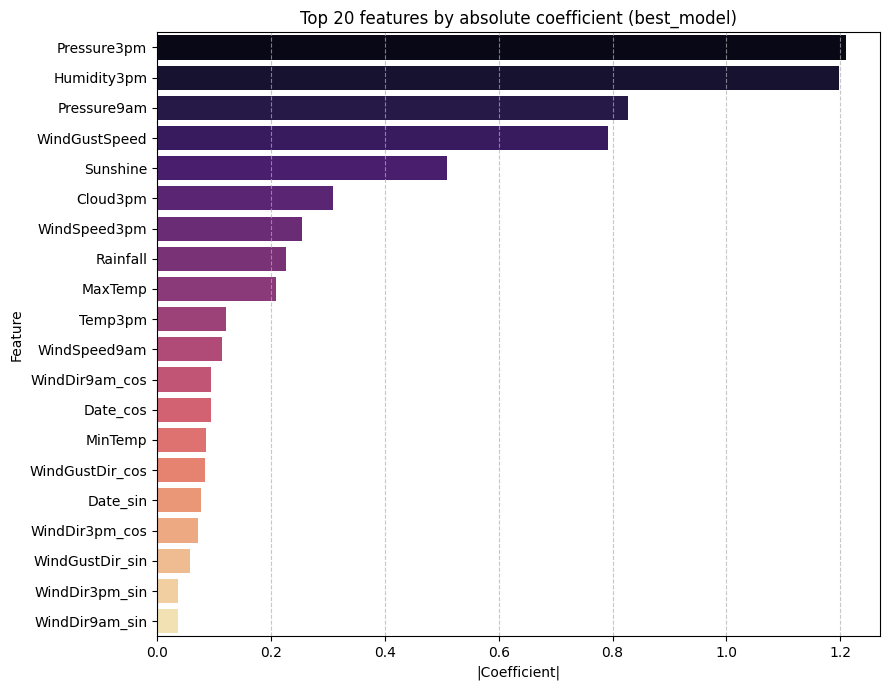

In [30]:
log_section('10. Bootstrap coefficient stability')

# Top-20 des variables par coefficient absolu du modèle unique ajusté (best_model)
coef_importance_full = pd.DataFrame({
    'Feature': X_train_scaled.columns,
    'Coefficient': best_model.coef_[0],
    'AbsCoefficient': np.abs(best_model.coef_[0]),
}).sort_values('AbsCoefficient', ascending=False)

print('Top 20 features by absolute coefficient (best_model):')
print(coef_importance_full.head(20).to_string(index=False, float_format='%.4f'))

fig = plt.figure(figsize=(9, 7))
sns.barplot(
    data=coef_importance_full.head(20),
    x='AbsCoefficient', y='Feature',
    hue='Feature', palette='magma', legend=False,
)
plt.title('Top 20 features by absolute coefficient (best_model)')
plt.xlabel('|Coefficient|')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
save_fig('05_top20_coefficients', fig)
plt.show()


In [31]:
N_BOOTSTRAP = 200
boot_coefs = []
boot_test_probs = []
boot_models = []   # conservés pour l'export de l'ensemble

for i in range(N_BOOTSTRAP):
    X_bs, y_bs = resample(X_train_scaled, y_train, replace=True, random_state=i)
    m = LogisticRegression(**best_model.get_params())
    m.fit(X_bs, y_bs)
    boot_models.append(m)
    boot_coefs.append(m.coef_[0])
    boot_test_probs.append(m.predict_proba(X_test_scaled)[:, 1])

boot_df = pd.DataFrame(boot_coefs, columns=X_train_scaled.columns)
boot_summary = pd.DataFrame({
    'mean':  boot_df.mean(),
    'std':   boot_df.std(),
    'q025':  boot_df.quantile(0.025),
    'q975':  boot_df.quantile(0.975),
    'abs_mean': boot_df.mean().abs(),
}).sort_values('abs_mean', ascending=False)

print(f'\nBootstrap complete (N={N_BOOTSTRAP}). Top-15 features:')
print(boot_summary.head(15).round(4).to_string())


/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C

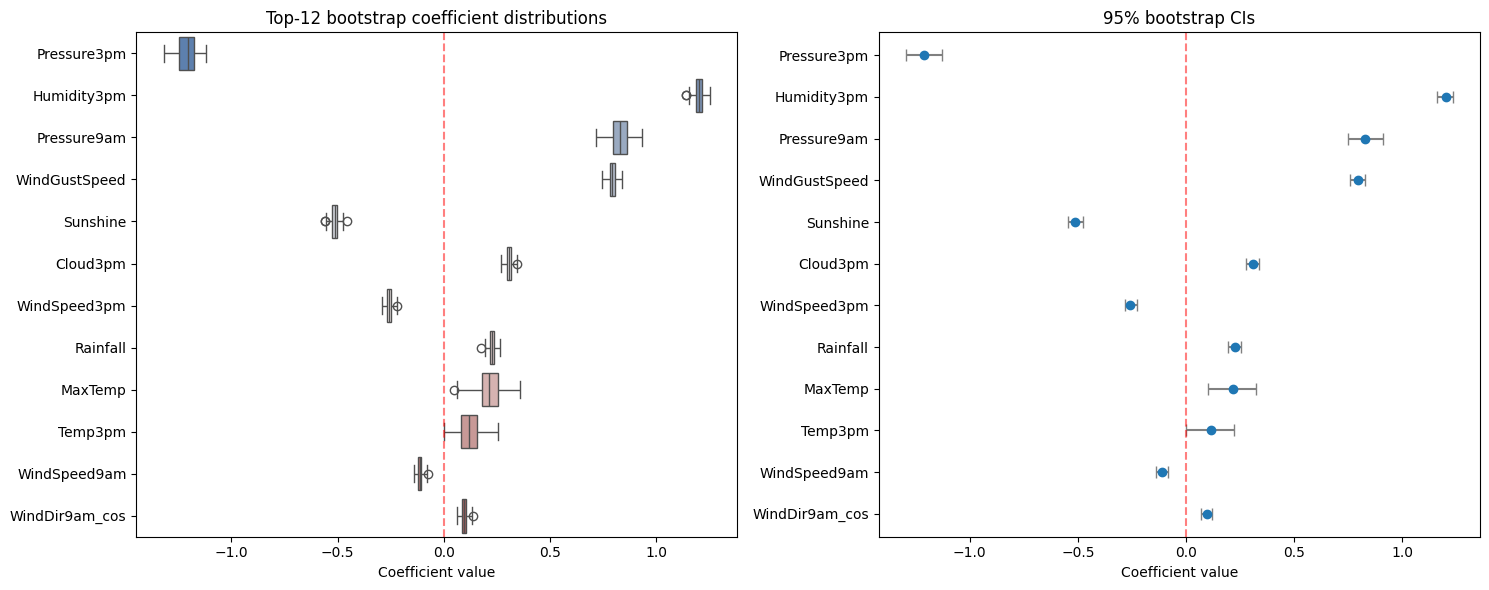

In [32]:
top_n = 12
top_feats = boot_summary.head(top_n).index

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.boxplot(data=boot_df[top_feats], orient='h', ax=axes[0], palette='vlag')
axes[0].axvline(0, color='red', linestyle='--', alpha=0.5)
axes[0].set_title(f'Top-{top_n} bootstrap coefficient distributions')
axes[0].set_xlabel('Coefficient value')

ci_data = boot_summary.loc[top_feats]
axes[1].errorbar(
    x=ci_data['mean'], y=ci_data.index,
    xerr=[ci_data['mean'] - ci_data['q025'], ci_data['q975'] - ci_data['mean']],
    fmt='o', ecolor='gray', capsize=4,
)
axes[1].axvline(0, color='red', linestyle='--', alpha=0.5)
axes[1].set_title('95% bootstrap CIs')
axes[1].set_xlabel('Coefficient value')
axes[1].invert_yaxis()
plt.tight_layout()
save_fig('06_bootstrap_stability', fig)
plt.show()


In [33]:
y_proba_bagged = np.mean(boot_test_probs, axis=0)
y_pred_bagged = (y_proba_bagged >= best_threshold)

print(f'\nBagged bootstrap (N={N_BOOTSTRAP}, threshold={best_threshold}) — classification report:')
print(classification_report(y_test, y_pred_bagged))
print(f'ROC-AUC : {roc_auc_score(y_test, y_proba_bagged):.4f}')


In [34]:
# Export — ensemble bootstrap (bagging)
# La prédiction d'ensemble est la moyenne des probabilités des N modèles : ils sont donc
# tous nécessaires. `boot_summary` est joint pour les intervalles de confiance du rapport.
path = MODELS_DIR / 'logistic_regression_bootstrap_bagged.joblib'
joblib.dump({'model': boot_models, 'n_bootstrap': N_BOOTSTRAP, 'threshold': best_threshold,
             'features': list(X_train_scaled.columns), 'scaler': scaler,
             'coef_summary': boot_summary,
             'metrics': {'f1_yes': f1_score(y_test, y_pred_bagged),
                         'precision_yes': precision_score(y_test, y_pred_bagged),
                         'recall_yes': recall_score(y_test, y_pred_bagged),
                         'roc_auc': roc_auc_score(y_test, y_proba_bagged)}}, path)
print(f'  [saved {path}]')


## 11. Analyse de calibration

Le ROC-AUC et le PR-AUC mesurent la *discrimination* — la capacité du modèle à classer les jours de pluie au-dessus des jours secs — et sont invariants par transformation monotone de la probabilité prédite. Ils ne disent donc rien sur le fait qu'un $\hat{p} = 0.7$ corresponde à un taux empirique de positifs de 70 %. Un modèle mal calibré peut classer parfaitement tout en produisant des probabilités systématiquement biaisées, ce qui devient un problème lorsque la probabilité elle-même est utilisée en aval (seuils de décision liés à des coûts attendus, moyenne d'ensemble, prévisions probabilistes).

Trois diagnostics :

- **Diagramme de fiabilité** : on regroupe les probabilités prédites en classes (bins), et on trace la probabilité moyenne prédite contre le taux empirique de positifs par classe. Une calibration parfaite correspond à la diagonale $y = x$.
- **Score de Brier** : $\frac{1}{N} \sum_i (\hat{p}_i - y_i)^2$. Une règle de score strictement propre qui se décompose en fiabilité + résolution + incertitude.
- **Erreur de calibration attendue (ECE)** : $\text{ECE} = \sum_b (|B_b|/N) \, |\text{acc}(B_b) - \text{conf}(B_b)|$, l'écart pondéré entre l'exactitude empirique et la confiance moyenne à travers $b$ classes.

Un modèle logistique régularisé en L2 entraîné sans repondération de classe est typiquement bien calibré, car la perte d'entropie croisée est elle-même la perte de calibration. Sous `class_weight='balanced'`, en revanche, la perte n'est plus l'objectif de maximum de vraisemblance : la repondération biaise les probabilités, les éloignant du taux de base empirique vers le taux équilibré, produisant une surestimation connue de la probabilité de la classe minoritaire. Nous mesurons cela directement sur les probabilités issues du modèle de référence, du modèle optimisé et du bagging bootstrap.

In [35]:
log_section('11. Calibration analysis')

def expected_calibration_error(y_true, y_prob, n_bins=10):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_idx = np.digitize(y_prob, bin_edges[1:-1])
    ece = 0.0
    n = len(y_true)
    for b in range(n_bins):
        mask = bin_idx == b
        if mask.sum() > 0:
            acc = y_true[mask].mean()
            conf = y_prob[mask].mean()
            ece += (mask.sum() / n) * abs(acc - conf)
    return ece

# Compute calibration on three probability sources
probs = {
    'baseline (no reweight)': y_proba_baseline,
    'tuned (best_model)':     y_proba_tuned,
    'bagged bootstrap':       y_proba_bagged,
}

calib_metrics = []
for name, p in probs.items():
    calib_metrics.append({
        'model':  name,
        'Brier':  brier_score_loss(y_test, p),
        'logloss': log_loss(y_test, np.clip(p, 1e-9, 1 - 1e-9)),
        'ECE_10': expected_calibration_error(y_test.values, p, n_bins=10),
        'mean_pred': float(np.mean(p)),
        'empirical_rate': float(y_test.mean()),
    })
calib_table = pd.DataFrame(calib_metrics).round(4)
print('\nCalibration metrics (three probability sources):')
print(calib_table.to_string(index=False))


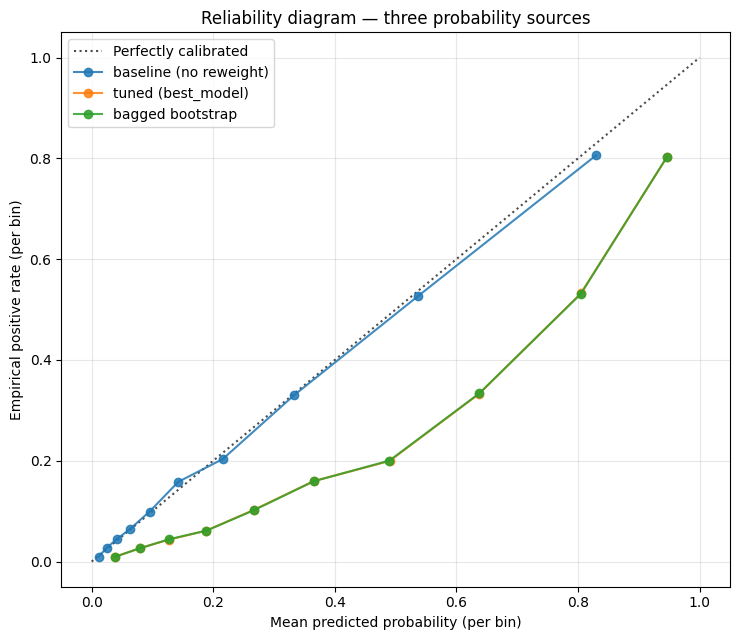

In [36]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot([0, 1], [0, 1], 'k:', label='Perfectly calibrated', alpha=0.7)
for name, p in probs.items():
    prob_true, prob_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    ax.plot(prob_pred, prob_true, 'o-', label=name, alpha=0.85)
ax.set_xlabel('Mean predicted probability (per bin)')
ax.set_ylabel('Empirical positive rate (per bin)')
ax.set_title('Reliability diagram — three probability sources')
ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('07_reliability_diagram', fig)
plt.show()


In [37]:
# Recalibration a posteriori : on découpe la période d'entraînement chronologiquement en
# (refit, calibrate), on ajuste les mappings isotonic et sigmoid sur la tranche de calibration,
# puis on évalue sur le jeu de test.

n_train = len(X_train_scaled)
calib_split = int(n_train * 0.85)
X_refit = X_train_scaled.iloc[:calib_split]
y_refit = y_train.iloc[:calib_split]
X_calib = X_train_scaled.iloc[calib_split:]
y_calib = y_train.iloc[calib_split:]

refit_model = LogisticRegression(**best_model.get_params())
refit_model.fit(X_refit, y_refit)

calib_iso = CalibratedClassifierCV(refit_model, method='isotonic', cv='prefit')
calib_iso.fit(X_calib, y_calib)

calib_sig = CalibratedClassifierCV(refit_model, method='sigmoid', cv='prefit')
calib_sig.fit(X_calib, y_calib)

y_proba_iso = calib_iso.predict_proba(X_test_scaled)[:, 1]
y_proba_sig = calib_sig.predict_proba(X_test_scaled)[:, 1]

rows = []
for name, p in [('refit (uncalibrated)', refit_model.predict_proba(X_test_scaled)[:, 1]),
                ('isotonic recalibrated', y_proba_iso),
                ('sigmoid (Platt) recalibrated', y_proba_sig)]:
    rows.append({
        'method': name,
        'Brier':  brier_score_loss(y_test, p),
        'logloss': log_loss(y_test, np.clip(p, 1e-9, 1 - 1e-9)),
        'ECE_10': expected_calibration_error(y_test.values, p, n_bins=10),
        'mean_pred': float(np.mean(p)),
        'ROC_AUC': roc_auc_score(y_test, p),
    })
recalib_table = pd.DataFrame(rows).round(4)
print('\nPost-hoc recalibration metrics:')
print(recalib_table.to_string(index=False))


/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


InvalidParameterError: The 'cv' parameter of CalibratedClassifierCV must be an int in the range [2, inf), an object implementing 'split' and 'get_n_splits', an iterable or None. Got 'prefit' instead.

In [ ]:
# Export — modèles recalibrés (isotonic et Platt)
# Le bundle embarque le calibrateur ET le modèle réajusté sous-jacent : `calib_iso` est
# ajusté en mode cv='prefit' et n'est donc pas utilisable sans `refit_model`.
path = MODELS_DIR / 'calibrated_isotonic.joblib'
joblib.dump({'model': calib_iso, 'base_estimator': refit_model, 'threshold': best_threshold,
             'features': list(X_train_scaled.columns), 'scaler': scaler,
             'calibration_split': calib_split,
             'metrics': {'brier': brier_score_loss(y_test, y_proba_iso),
                         'logloss': log_loss(y_test, np.clip(y_proba_iso, 1e-9, 1 - 1e-9)),
                         'ece_10': expected_calibration_error(y_test.values, y_proba_iso, n_bins=10),
                         'roc_auc': roc_auc_score(y_test, y_proba_iso)}}, path)
print(f'  [saved {path}]')

path = MODELS_DIR / 'calibrated_sigmoid.joblib'
joblib.dump({'model': calib_sig, 'base_estimator': refit_model, 'threshold': best_threshold,
             'features': list(X_train_scaled.columns), 'scaler': scaler,
             'calibration_split': calib_split,
             'metrics': {'brier': brier_score_loss(y_test, y_proba_sig),
                         'logloss': log_loss(y_test, np.clip(y_proba_sig, 1e-9, 1 - 1e-9)),
                         'ece_10': expected_calibration_error(y_test.values, y_proba_sig, n_bins=10),
                         'roc_auc': roc_auc_score(y_test, y_proba_sig)}}, path)
print(f'  [saved {path}]')


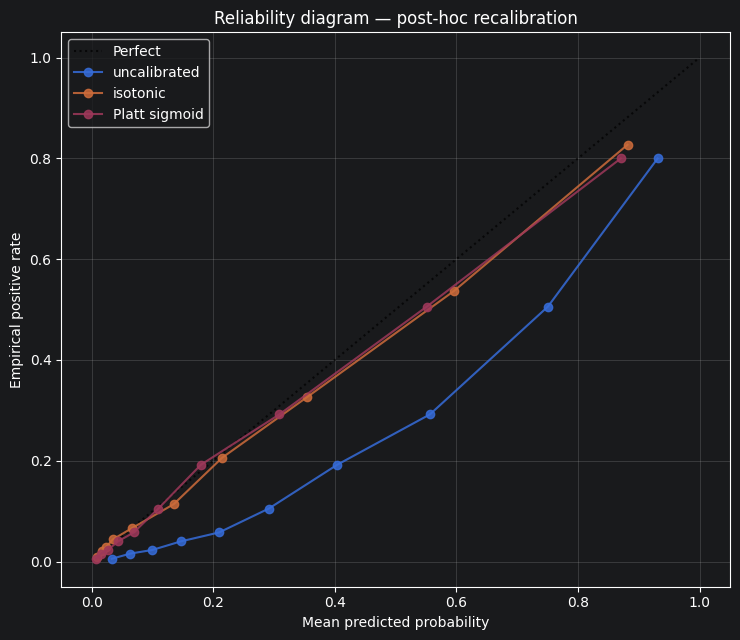

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.plot([0, 1], [0, 1], 'k:', alpha=0.7, label='Perfect')
for name, p in [('uncalibrated', refit_model.predict_proba(X_test_scaled)[:, 1]),
                ('isotonic', y_proba_iso),
                ('Platt sigmoid', y_proba_sig)]:
    prob_true, prob_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    ax.plot(prob_pred, prob_true, 'o-', label=name, alpha=0.85)
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Empirical positive rate')
ax.set_title('Reliability diagram — post-hoc recalibration')
ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('08_recalibration_reliability_diagram', fig)
plt.show()


## 12. Courbes d'évaluation finale

Courbes ROC et Précision–Rappel pour les trois principales sources de probabilité (optimisé, bagging bootstrap, recalibré par isotonic), suivies d'une courbe d'apprentissage sous validation croisée `TimeSeriesSplit` montrant l'évolution du F1 d'entraînement et de validation avec la taille de l'échantillon.

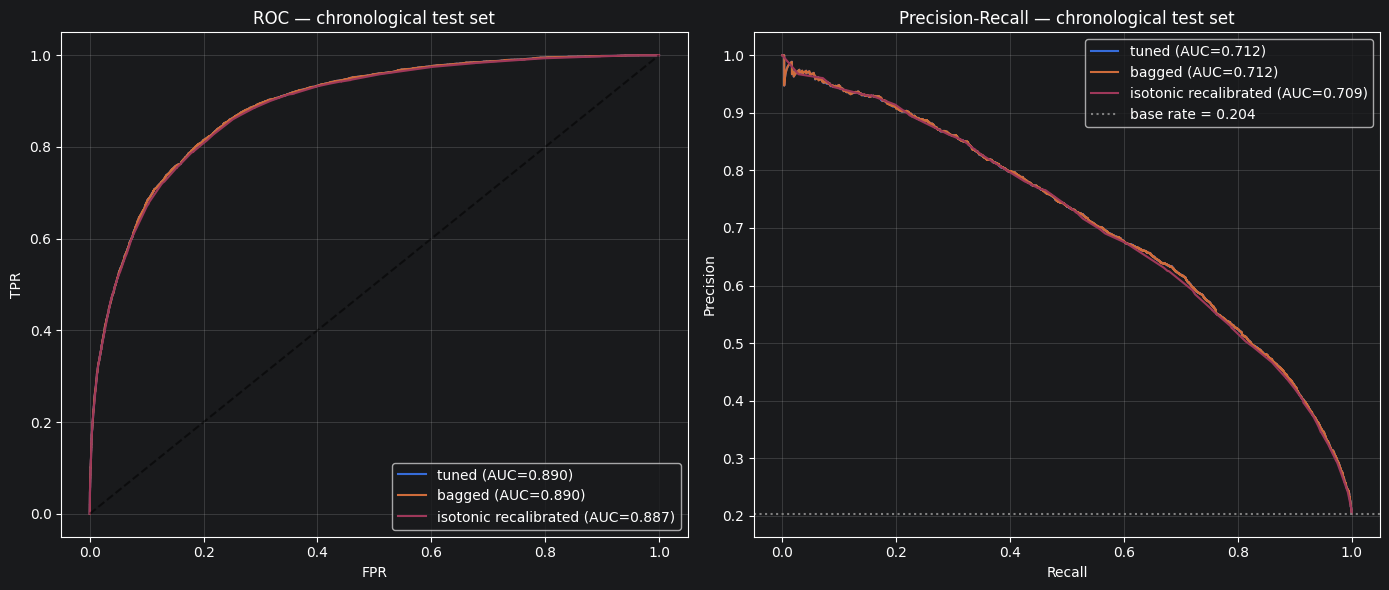

In [ ]:
log_section('12. Final evaluation curves')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ROC
roc_aucs = {}
for name, p in [('tuned', y_proba_tuned),
                ('bagged', y_proba_bagged),
                ('isotonic recalibrated', y_proba_iso)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    auc_v = roc_auc_score(y_test, p)
    roc_aucs[name] = auc_v
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc_v:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC — chronological test set')
axes[0].legend(loc='lower right'); axes[0].grid(alpha=0.3)

# PR
base_rate = float(y_test.mean())
pr_aucs = {}
for name, p in [('tuned', y_proba_tuned),
                ('bagged', y_proba_bagged),
                ('isotonic recalibrated', y_proba_iso)]:
    pr, rc, _ = precision_recall_curve(y_test, p)
    pr_auc = auc(rc, pr)
    pr_aucs[name] = pr_auc
    axes[1].plot(rc, pr, label=f'{name} (AUC={pr_auc:.3f})')
axes[1].axhline(base_rate, color='gray', linestyle=':', label=f'base rate = {base_rate:.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall — chronological test set')
axes[1].legend(loc='upper right'); axes[1].grid(alpha=0.3)
plt.tight_layout()
save_fig('09_roc_pr_curves', fig)
plt.show()

print('\nROC-AUC by source:')
for name, v in roc_aucs.items():
    print(f'  {name:30s} {v:.4f}')
print('PR-AUC by source:')
for name, v in pr_aucs.items():
    print(f'  {name:30s} {v:.4f}')
print(f'Base rate (positive class fraction in test set): {base_rate:.4f}')


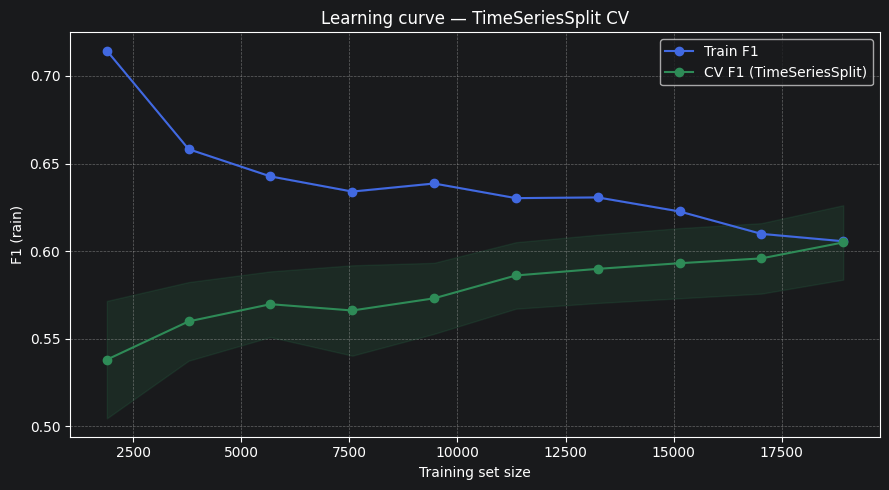

In [ ]:
estimator = LogisticRegression(**best_model.get_params())
train_sizes, train_scores, val_scores = learning_curve(
    estimator, X_train_scaled, y_train,
    cv=ts_cv, scoring='f1', n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10),
)
tr_m, tr_s = train_scores.mean(1), train_scores.std(1)
vl_m, vl_s = val_scores.mean(1), val_scores.std(1)

print('\nLearning curve — train and CV F1 by training set size:')
lc_df = pd.DataFrame({
    'train_size': train_sizes,
    'train_F1_mean': tr_m,
    'train_F1_std':  tr_s,
    'cv_F1_mean':    vl_m,
    'cv_F1_std':     vl_s,
})
print(lc_df.to_string(index=False, float_format='%.4f'))

fig = plt.figure(figsize=(9, 5))
plt.plot(train_sizes, tr_m, 'o-', color='royalblue', label='Train F1')
plt.fill_between(train_sizes, tr_m - tr_s, tr_m + tr_s, alpha=0.15, color='royalblue')
plt.plot(train_sizes, vl_m, 'o-', color='seagreen', label='CV F1 (TimeSeriesSplit)')
plt.fill_between(train_sizes, vl_m - vl_s, vl_m + vl_s, alpha=0.15, color='seagreen')
plt.xlabel('Training set size'); plt.ylabel('F1 (rain)')
plt.title('Learning curve — TimeSeriesSplit CV')
plt.legend(); plt.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
save_fig('10_learning_curve', fig)
plt.show()


## Finalisation

Fermer le fichier de résultats et lister les artefacts produits.

In [42]:
log_section('Finalization')

print(f'Results file: {_LR_RESULT_PATH}')
fig_files = sorted(f for f in os.listdir('../reports/figures') if f.lower().endswith('.png'))
print(f'Figures saved ({len(fig_files)}):')
for f in fig_files:
    print(f'  ../reports/figures/{f}')

model_files = sorted(MODELS_DIR.glob('*.joblib'))
print(f'\nModels exported to {MODELS_DIR} ({len(model_files)}):')
for f in model_files:
    print(f'  {f.name:<28} {f.stat().st_size / 1024:>8.1f} KB')

# Restaurer stdout et fermer le fichier de log
sys.stdout = _ORIG_STDOUT
_LR_RESULT_FILE.close()
print(f'\nDone. See {_LR_RESULT_PATH}, ../reports/figures/ and {MODELS_DIR}/ for outputs.')